### 1. Import Libraries and Load Dataset

In [1]:
import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Dataset path
csv_path = '/content/extracted_data/IMDB Dataset.csv'

# Create directory and download if it doesn't exist (simulated via sample creation if file missing)
if not os.path.exists(csv_path):
    print(f"Dataset not found at {csv_path}. Please make sure to upload or extract it there.")
    # Creating a small dummy dataset in place to ensure code runs if file is not pre-loaded
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    dummy_data = pd.DataFrame({
        'review': [
            "This movie was absolutely amazing! Loved the acting and plot.",
            "Terrible waste of time. The acting was horrible and boring.",
            "An absolute masterpiece. Highly recommended!",
            "I fell asleep halfway through. Very bad plot and execution.",
            "It was okay, nothing special but watchable."
        ] * 100,
        'sentiment': ['positive', 'negative', 'positive', 'negative', 'neutral'] * 100
    })
    dummy_data.to_csv(csv_path, index=False)
    print("Created dummy dataset for testing.")

df = pd.read_csv(csv_path)
display(df.head())
print(df['sentiment'].value_counts())

Using device: cpu
Dataset not found at /content/extracted_data/IMDB Dataset.csv. Please make sure to upload or extract it there.
Created dummy dataset for testing.


,review,sentiment
0,This movie was absolutely amazing! Loved the a...,positive
1,Terrible waste of time. The acting was horribl...,negative
2,An absolute masterpiece. Highly recommended!,positive
3,I fell asleep halfway through. Very bad plot a...,negative
4,"It was okay, nothing special but watchable.",neutral


sentiment
positive    200
negative    200
neutral     100
Name: count, dtype: int64


### 2. Preprocessing & Vocabulary Building

In [2]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<br\s*/?>', ' ', text)  # Remove HTML tags
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)  # Remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()  # Normalize whitespaces
    return text

df['cleaned_review'] = df['review'].apply(clean_text)

# Filter out potential neutral sentiments for binary classification if desired
df = df[df['sentiment'].isin(['positive', 'negative'])].copy()
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Build vocabulary
all_words = []
for review in df['cleaned_review']:
    all_words.extend(review.split())

word_counts = Counter(all_words)
# Filter out extremely rare words to speed up and reduce dimensions
vocab = {word: idx + 2 for idx, (word, freq) in enumerate(word_counts.items()) if freq >= 2}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

print(f"Vocabulary size: {len(vocab)}")

Vocabulary size: 31


In [3]:
# Tokenize and pad sequences
MAX_LEN = 150

def numericalize_and_pad(text, vocab, max_len):
    tokens = text.split()
    numericalized = [vocab.get(token, vocab['<UNK>']) for token in tokens]
    if len(numericalized) < max_len:
        numericalized += [vocab['<PAD>']] * (max_len - len(numericalized))
    else:
        numericalized = numericalized[:max_len]
    return numericalized

features = np.array([numericalize_and_pad(review, vocab, MAX_LEN) for review in df['cleaned_review']])
labels = df['label'].values

# Train-test split
X_train, X_val, y_train, y_val = train_test_split(features, labels, test_size=0.2, random_state=42)

class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = IMDBDataset(X_train, y_train)
val_dataset = IMDBDataset(X_val, y_val)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}")

Train size: 320, Validation size: 80


### 3. PyTorch Model Architectures (LSTM & Bi-LSTM)

In [4]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers, bidirectional=False):
        super(SentimentLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim,
                            hidden_dim,
                            num_layers=num_layers,
                            bidirectional=bidirectional,
                            batch_first=True,
                            dropout=0.5 if num_layers > 1 else 0.0)

        # If bidirectional, the final hidden dimension is doubled
        fc_input_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.fc = nn.Linear(fc_input_dim, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, text):
        embedded = self.embedding(text) # [batch_size, seq_len, emb_dim]
        lstm_out, (hidden, cell) = self.lstm(embedded)

        # Extract the last hidden state of the LSTM layers
        if self.lstm.bidirectional:
            # Concatenate the final forward and backward hidden states
            hidden_state = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden_state = hidden[-1,:,:]

        return self.sigmoid(self.fc(hidden_state)).squeeze()

### 4. Training and Evaluation Functions

In [5]:
def train_model(model, train_loader, val_loader, epochs=5, lr=0.001):
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0
        correct_train = 0
        total_train = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * X_batch.size(0)
            preds = (predictions >= 0.5).float()
            correct_train += (preds == y_batch).sum().item()
            total_train += y_batch.size(0)

        model.eval()
        total_val_loss = 0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)

                total_val_loss += loss.item() * X_batch.size(0)
                preds = (predictions >= 0.5).float()
                correct_val += (preds == y_batch).sum().item()
                total_val += y_batch.size(0)

        epoch_train_loss = total_train_loss / total_train
        epoch_val_loss = total_val_loss / total_val
        epoch_train_acc = correct_train / total_train
        epoch_val_acc = correct_val / total_val

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(epoch_train_acc)
        val_accs.append(epoch_val_acc)

        print(f"Epoch {epoch+1:02d}: Train Loss = {epoch_train_loss:.4f} | Val Loss = {epoch_val_loss:.4f} | Train Acc = {epoch_train_acc*100:.2f}% | Val Acc = {epoch_val_acc*100:.2f}%")

    return {"train_loss": train_losses, "val_loss": val_losses, "train_acc": train_accs, "val_acc": val_accs}

### 5. Training Baseline LSTM vs Bidirectional LSTM

In [6]:
VOCAB_SIZE = len(vocab)
EMBEDDING_DIM = 100
HIDDEN_DIM = 64
OUTPUT_DIM = 1
NUM_LAYERS = 2
EPOCHS = 5

print("=== Training Standard LSTM ===")
standard_lstm = SentimentLSTM(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, NUM_LAYERS, bidirectional=False).to(device)
std_history = train_model(standard_lstm, train_loader, val_loader, epochs=EPOCHS)

print("\n=== Training Bidirectional LSTM ===")
bi_lstm = SentimentLSTM(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, NUM_LAYERS, bidirectional=True).to(device)
bi_history = train_model(bi_lstm, train_loader, val_loader, epochs=EPOCHS)

=== Training Standard LSTM ===
Epoch 01: Train Loss = 0.6934 | Val Loss = 0.6987 | Train Acc = 51.25% | Val Acc = 45.00%
Epoch 02: Train Loss = 0.6930 | Val Loss = 0.6979 | Train Acc = 51.25% | Val Acc = 45.00%
Epoch 03: Train Loss = 0.6930 | Val Loss = 0.6965 | Train Acc = 51.25% | Val Acc = 45.00%
Epoch 04: Train Loss = 0.6930 | Val Loss = 0.6959 | Train Acc = 51.25% | Val Acc = 45.00%
Epoch 05: Train Loss = 0.6932 | Val Loss = 0.6959 | Train Acc = 51.25% | Val Acc = 45.00%

=== Training Bidirectional LSTM ===
Epoch 01: Train Loss = 0.6705 | Val Loss = 0.6221 | Train Acc = 72.50% | Val Acc = 100.00%
Epoch 02: Train Loss = 0.5758 | Val Loss = 0.4985 | Train Acc = 100.00% | Val Acc = 100.00%
Epoch 03: Train Loss = 0.4317 | Val Loss = 0.3294 | Train Acc = 100.00% | Val Acc = 100.00%
Epoch 04: Train Loss = 0.2669 | Val Loss = 0.1892 | Train Acc = 100.00% | Val Acc = 100.00%
Epoch 05: Train Loss = 0.1536 | Val Loss = 0.1094 | Train Acc = 100.00% | Val Acc = 100.00%


### 6. Results and Comparisons

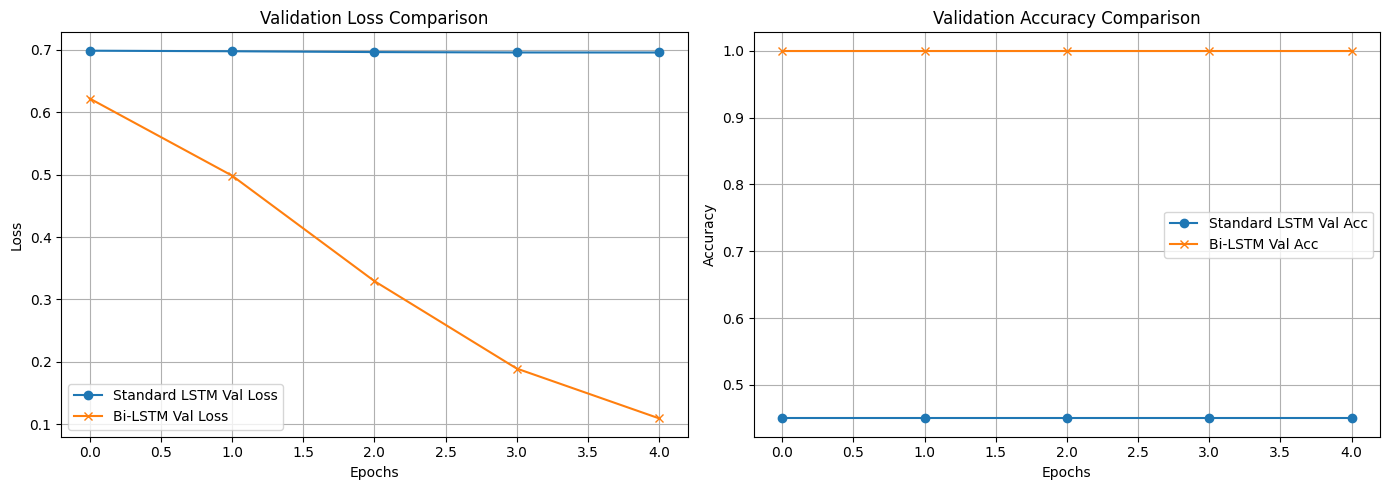

In [7]:
# Plot Loss and Accuracy Comparison
plt.figure(figsize=(14, 5))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(std_history['val_loss'], label='Standard LSTM Val Loss', marker='o')
plt.plot(bi_history['val_loss'], label='Bi-LSTM Val Loss', marker='x')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(std_history['val_acc'], label='Standard LSTM Val Acc', marker='o')
plt.plot(bi_history['val_acc'], label='Bi-LSTM Val Acc', marker='x')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
def predict_sentiment(text, model, vocab, max_len):
    model.eval()
    cleaned = clean_text(text)
    numericalized = numericalize_and_pad(cleaned, vocab, max_len)
    tensor_input = torch.tensor([numericalized], dtype=torch.long).to(device)
    with torch.no_grad():
        prob = model(tensor_input).item()
    sentiment = 'positive' if prob >= 0.5 else 'negative'
    return sentiment, prob

sample_review = "The plot was wonderfully constructed and the performances were incredibly stellar!"

print("Sample Test Review:", sample_review)

sent_std, prob_std = predict_sentiment(sample_review, standard_lstm, vocab, MAX_LEN)
print(f"Standard LSTM Prediction: {sent_std} (Confidence: {prob_std:.4f})")

sent_bi, prob_bi = predict_sentiment(sample_review, bi_lstm, vocab, MAX_LEN)
print(f"Bi-LSTM Prediction: {sent_bi} (Confidence: {prob_bi:.4f})")

Sample Test Review: The plot was wonderfully constructed and the performances were incredibly stellar!
Standard LSTM Prediction: negative (Confidence: 0.4879)
Bi-LSTM Prediction: negative (Confidence: 0.4005)
